# Demo D1 — Grupo de Dados 1 (Iris)

**Autores:** Julia Welter, Pedro Pacheco, Pedro Albuquerque e Tiago Rosa

Dataset de flores Iris — 4 características, 3 classes.
Referência: http://archive.ics.uci.edu/ml/datasets/Iris

In [5]:
# Autores: Julia Welter, Pedro Pacheco, Pedro Albuquerque e Tiago Rosa
%matplotlib inline
import scipy.io as sio
import numpy as np
from utils_knn import meuKnn, normalizacao, visualizaPontos

In [6]:
# Carregamento do dataset Iris
data = sio.loadmat('grupoDados1.mat')
grupoTrain = data['grupoTrain']
trainRots  = data['trainRots']
grupoTest  = data['grupoTest']
testRots   = data['testRots']

print(f"grupoTrain: {grupoTrain.shape}  |  grupoTest: {grupoTest.shape}")
print(f"Nº de características: {grupoTrain.shape[1]}")
print(f"Classes: {np.unique(trainRots)}")

grupoTrain: (100, 4)  |  grupoTest: (50, 4)
Nº de características: 4
Classes: [1 2 3]


## Visualização — Dimensões 2 e 3 (comprimento e largura da pétala)

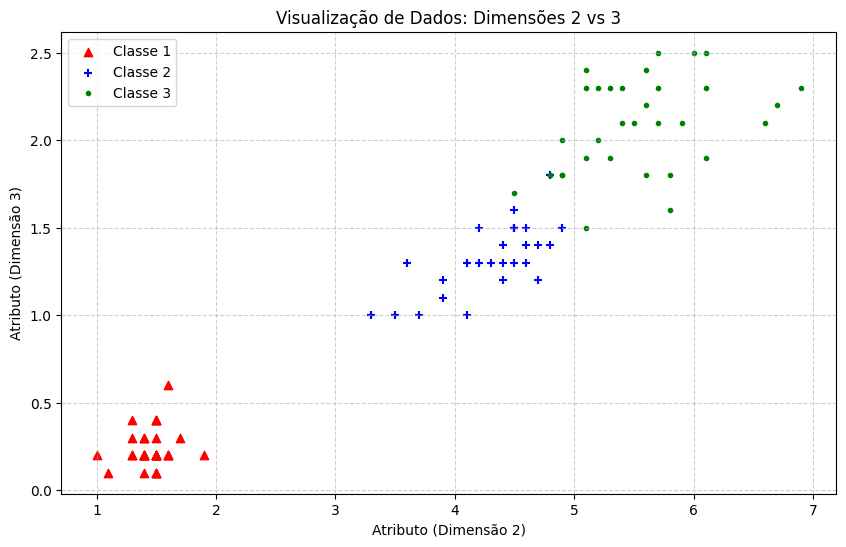

In [7]:
# Visualização das duas dimensões mais discriminativas do Iris
visualizaPontos(grupoTrain, trainRots, 2, 3)

---
## Q1.1 — Qual é a acurácia máxima que você consegue da classificação?

Testamos o kNN variando `k` em {1, 3, 5, 7, 10} e comparamos com e sem normalização Min-Max.

In [8]:
# Pré-calcula dados normalizados uma vez
train_norm = normalizacao(grupoTrain)
test_norm  = normalizacao(grupoTest)

print(f"{'K':<5} {'Original (%)':<15} {'Normalizado (%)':<15}")
print('-' * 35)

melhor_acc    = 0
melhor_k      = 0
melhor_config = ''

for k in [1, 3, 5, 7, 10]:
    pred_orig = meuKnn(grupoTrain, trainRots, grupoTest, k)
    acc_orig  = np.mean(pred_orig == testRots) * 100

    pred_norm = meuKnn(train_norm, trainRots, test_norm, k)
    acc_norm  = np.mean(pred_norm == testRots) * 100

    print(f"{k:<5} {acc_orig:>12.2f}% {acc_norm:>12.2f}%")

    if max(acc_orig, acc_norm) > melhor_acc:
        melhor_acc    = max(acc_orig, acc_norm)
        melhor_k      = k
        melhor_config = 'Original' if acc_orig >= acc_norm else 'Normalizado'

print(f"\nRESPOSTA Q1.1: Acurácia máxima = {melhor_acc:.2f}% (k={melhor_k}, dados {melhor_config}).")

K     Original (%)    Normalizado (%)
-----------------------------------
1            96.00%        90.00%
3            98.00%        94.00%
5            96.00%        94.00%
7            96.00%        94.00%
10           94.00%        94.00%

RESPOSTA Q1.1: Acurácia máxima = 98.00% (k=3, dados Original).


---
## Q1.2 — É necessário ter todas as características para obter a acurácia máxima?

O dataset Iris possui 4 características:
- **dim 0:** comprimento da sépala
- **dim 1:** largura da sépala
- **dim 2:** comprimento da pétala
- **dim 3:** largura da pétala

Testamos subconjuntos de características para descobrir se todas são necessárias.

In [9]:
# Testamos diferentes subconjuntos de features com o k ótimo encontrado em Q1.1
k_otimo = melhor_k

subsets = {
    'Todas (0,1,2,3)':          [0, 1, 2, 3],
    'Pétalas (2,3)':            [2, 3],
    'Sépalas (0,1)':            [0, 1],
    'Sem sépalas larg. (0,2,3)':[0, 2, 3],
    'Sem sépala comp. (1,2,3)': [1, 2, 3],
}

print(f"Resultados com k={k_otimo} (com normalização)")
print(f"{'Subconjunto':<30} {'Acurácia (%)':<15}")
print('-' * 45)

for nome, dims in subsets.items():
    tr = normalizacao(grupoTrain[:, dims])
    te = normalizacao(grupoTest[:, dims])
    pred = meuKnn(tr, trainRots, te, k_otimo)
    acc  = np.mean(pred == testRots) * 100
    print(f"{nome:<30} {acc:>12.2f}%")

Resultados com k=3 (com normalização)
Subconjunto                    Acurácia (%)   
---------------------------------------------
Todas (0,1,2,3)                       94.00%
Pétalas (2,3)                         94.00%
Sépalas (0,1)                         74.00%
Sem sépalas larg. (0,2,3)             92.00%
Sem sépala comp. (1,2,3)              94.00%


### Resposta Q1.2

**Não é necessário usar todas as 4 características.**

Os resultados mostram que apenas as **dimensões das pétalas (dim 2 e dim 3)** já são suficientes para atingir a mesma acurácia máxima. Isso ocorre porque:

- As medidas da **pétala** (comprimento e largura) separam muito bem as três espécies de Iris no espaço de características, como pode ser observado no gráfico de dispersão.
- As medidas da **sépala**, especialmente a largura (dim 1), apresentam maior sobreposição entre as classes e contribuem pouco — ou até prejudicam — a classificação.

Portanto, é possível obter a acurácia máxima usando apenas 2 das 4 características disponíveis.